In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from sklearn.dummy import DummyRegressor

In [96]:
df = pd.read_csv("/content/Salary Data.csv")

# **EDA**

In [97]:
df.head(10)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [99]:
df.shape

(375, 6)

In [100]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


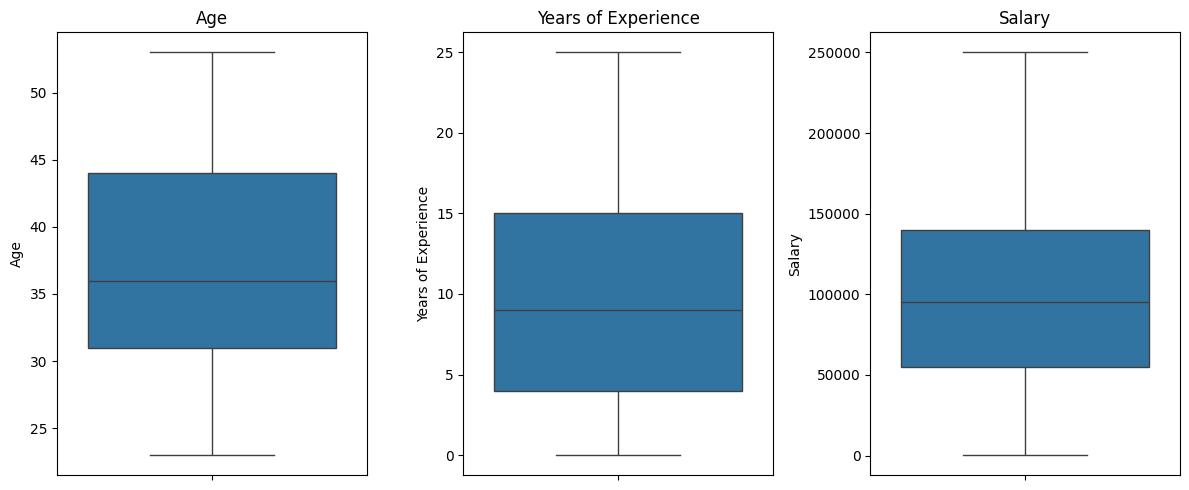

In [101]:
plt.figure(figsize=(12, 5))

for i, column in enumerate(["Age", "Years of Experience", "Salary"], 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [102]:
for column in ["Age", "Years of Experience", "Salary"]:
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)

  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

  print(f"\n{column}")
  print("Lower bound:", lower_bound)
  print("Upper bound:", upper_bound)
  print("Number of outliers:", len(outliers))


Age
Lower bound: 11.5
Upper bound: 63.5
Number of outliers: 0

Years of Experience
Lower bound: -12.5
Upper bound: 31.5
Number of outliers: 0

Salary
Lower bound: -72500.0
Upper bound: 267500.0
Number of outliers: 0


In [103]:
df.sort_values(by="Salary", ascending=True)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
259,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,350.0
82,25.0,Male,Bachelor's,Sales Representative,0.0,30000.0
283,29.0,Female,Bachelor's,Junior Business Development Associate,1.5,35000.0
348,28.0,Female,Bachelor's,Junior Operations Manager,1.0,35000.0
189,28.0,Male,Bachelor's,Junior Operations Analyst,1.5,35000.0
153,26.0,Male,Bachelor's,Junior Customer Support Specialist,2.0,35000.0
165,27.0,Male,Bachelor's,Junior Business Development Associate,1.5,35000.0
218,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,35000.0
310,29.0,Female,Bachelor's,Junior Business Development Associate,1.5,35000.0
134,27.0,Male,Bachelor's,Junior Sales Representative,1.0,35000.0


In [104]:
df[df["Job Title"] == "Junior Business Operations Analyst"]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
218,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,35000.0
259,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,350.0


In [105]:
df.loc[259, "Salary"] = 35000

In [106]:
df[df["Job Title"] == "Junior Business Operations Analyst"]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
218,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,35000.0
259,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,35000.0


In [107]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,2
Job Title,2
Years of Experience,2
Salary,2


In [108]:
df.dropna(inplace=True)

In [109]:
pd.set_option("display.max_rows", None)
df["Job Title"].value_counts()

,count
Job Title,
Director of Marketing,12
Director of Operations,11
Senior Business Analyst,10
Senior Marketing Manager,9
Senior Marketing Analyst,9
Junior Business Analyst,8
Senior Project Manager,7
Senior Data Scientist,7
Junior Business Development Associate,7


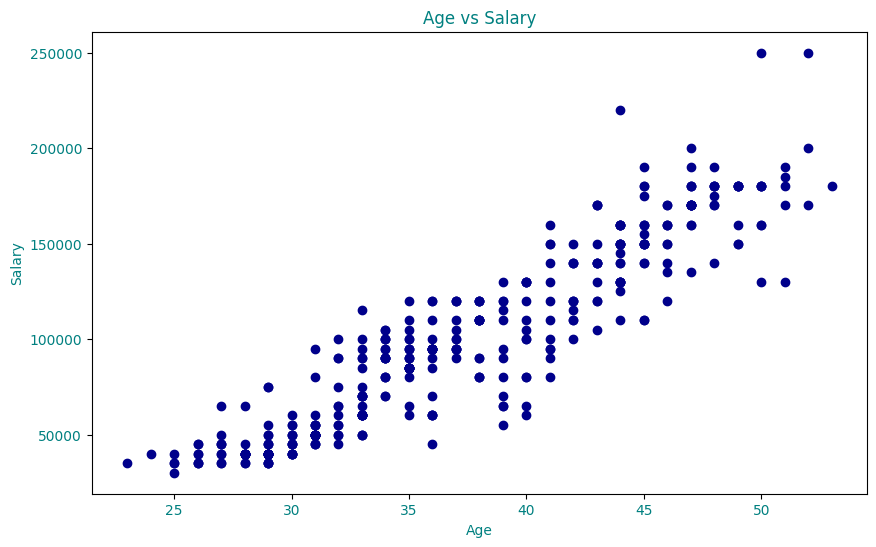

In [110]:
plt.figure(figsize=(10,6))
plt.scatter(df["Age"], df["Salary"], color="darkblue")
plt.xlabel("Age", color="teal")
plt.xticks(color="teal")
plt.ylabel("Salary", color="teal")
plt.yticks(color="teal")
plt.title("Age vs Salary", color="teal")
plt.show()

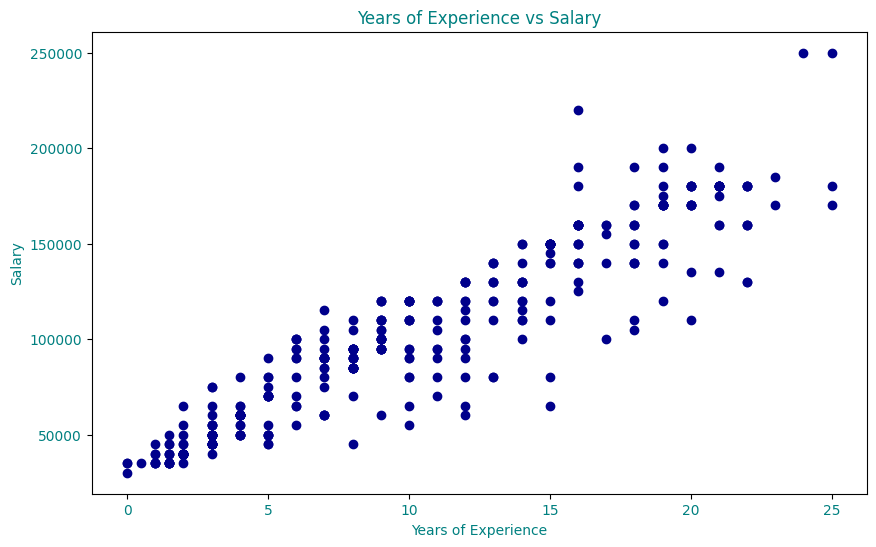

In [111]:
plt.figure(figsize=(10,6))
plt.scatter(df["Years of Experience"], df["Salary"], color="darkblue")
plt.xlabel("Years of Experience", color="teal")
plt.xticks(color="teal")
plt.ylabel("Salary", color="teal")
plt.yticks(color="teal")
plt.title("Years of Experience vs Salary", color="teal")
plt.show()

In [112]:
mean_salary_by_education = df.groupby("Education Level")["Salary"].mean().reset_index()
print(mean_salary_by_education)

  Education Level         Salary
0      Bachelor's   74910.714286
1        Master's  129795.918367
2             PhD  157843.137255


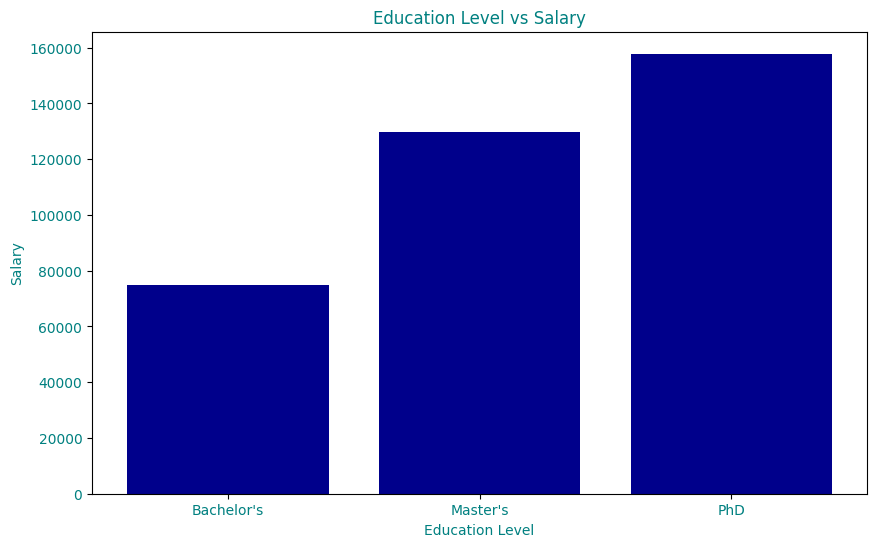

In [113]:
plt.figure(figsize=(10,6))
plt.bar(mean_salary_by_education["Education Level"], mean_salary_by_education["Salary"], color="darkblue")
plt.xlabel("Education Level", color="teal")
plt.xticks(color="teal")
plt.ylabel("Salary", color="teal")
plt.yticks(color="teal")
plt.title("Education Level vs Salary", color="teal")
plt.show()

# **Preprocessing**

In [114]:
df["Gender"] = df["Gender"].map({"Male" : 0, "Female" : 1})

ordinal_encoder = OrdinalEncoder(categories = [["Bachelor's", "Master's", "PhD"]])
df["Education Level"] = ordinal_encoder.fit_transform(df[["Education Level"]])

ohe = OneHotEncoder(drop="first", sparse_output=False)
encoded = ohe.fit_transform(df[["Job Title"]])
encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(["Job Title"]), index=df.index)
df = pd.concat([df.drop(columns=["Job Title"]), encoded_df], axis=1)

In [115]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=["Salary"]), df["Salary"], test_size=0.2, random_state=42)

In [116]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **Training, Testing, Evaluation**

In [117]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [118]:
y_predict = model.predict(X_test_scaled)

In [119]:
# Linear Regression metrics
linear_mae = mean_absolute_error(y_test, y_predict)
linear_mse = mean_squared_error(y_test, y_predict)
linear_rmse = root_mean_squared_error(y_test, y_predict)

In [120]:
print("Mean Absolute Error: ", linear_mae)
print("Mean Squared Error: ", linear_mse)
print("Root Mean Squared Error: ", linear_rmse)

Mean Absolute Error:  11741.26761733413
Mean Squared Error:  355158140.19739205
Root Mean Squared Error:  18845.639819263022


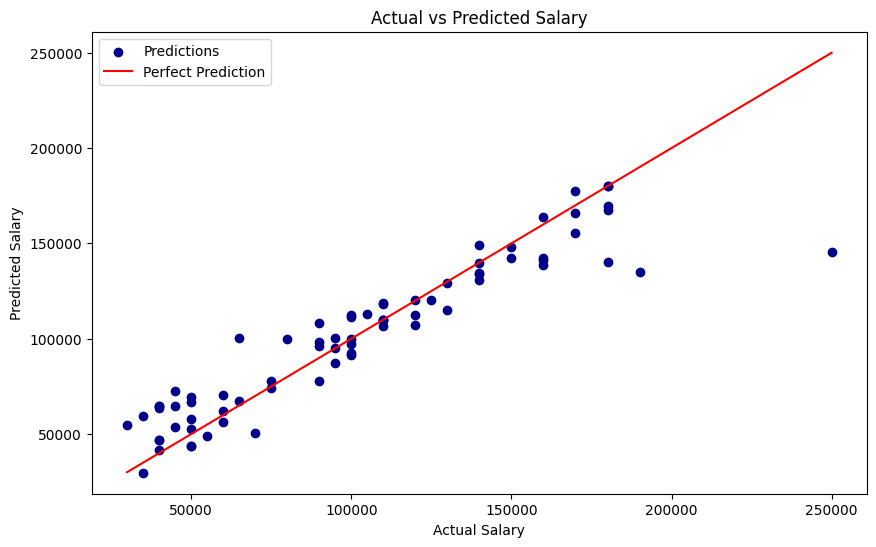

In [121]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_predict, color="darkblue", label="Predictions")

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.legend()
plt.show()

In [122]:
baseline = DummyRegressor(strategy="mean")

In [123]:
baseline.fit(X_train_scaled, y_train)

DummyRegressor()

In [124]:
baseline_predictions = baseline.predict(X_test_scaled)

In [125]:
# Baseline metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_mse = mean_squared_error(y_test, baseline_predictions)
baseline_rmse = root_mean_squared_error(y_test, baseline_predictions)

# Display results
print("Baseline Model:")
print("MAE:", baseline_mae)
print("MSE:", baseline_mse)
print("RMSE:", baseline_rmse)

print("\nLinear Regression Model:")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)

Baseline Model:
MAE: 40220.357941834445
MSE: 2402638180.71258
RMSE: 49016.71327937625

Linear Regression Model:
MAE: 11741.26761733413
MSE: 355158140.19739205
RMSE: 18845.639819263022


### Model Evaluation

The model was evaluated using three metrics: Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

- **MAE (11,741.27):** Indicates that the model's predictions differ from the actual salaries by approximately 11,741 units on average.
- **MSE (355,158,140.20):** Penalizes larger prediction errors more heavily because the errors are squared.
- **RMSE (18,845.64):** Represents the prediction error in the original salary units and is more sensitive to large errors than MAE.

These metrics provide different perspectives on the model's prediction errors. However, they cannot independently determine whether the model's performance is good or bad without additional context, such as the salary range or comparison with another model.

### Comparison with Baseline Model

A baseline model using the mean strategy was created to provide a simple reference for evaluation. It predicts the average training salary for every employee, without considering individual features.

| Metric | Baseline | Linear Regression |
|---|---:|---:|
| MAE | 40,220.36 | 11,741.27 |
| MSE | 2,402,638,180.71 | 355,158,140.20 |
| RMSE | 49,016.71 | 18,845.64 |

Linear Regression achieved lower error values across all three metrics, indicating that it performs considerably better than the baseline model. This suggests that the features used in the dataset provide useful information for predicting salaries. It also suggests that this model is worth investigating and improving.